In [1]:
import os
from scipy.io import loadmat
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
import re

In [2]:
import warnings
warnings.filterwarnings('ignore')

In [3]:
mat_files = [f for f in os.listdir('.') if f.endswith('_C_results.mat')]

data_dict = {}

for file in mat_files:
    data = loadmat(file)
    data_dict[file] = data  

for filename, content in data_dict.items():
    print(f"{filename}: keys = {list(content.keys())}")

94_C_results.mat: keys = ['__header__', '__version__', '__globals__', 'C_trace_region', 'C_trace_region2', 'timestamps', 'unique_area']
370_C_results.mat: keys = ['__header__', '__version__', '__globals__', 'C_trace_region', 'C_trace_region2', 'timestamps', 'unique_area']
369_C_results.mat: keys = ['__header__', '__version__', '__globals__', 'C_trace_region', 'C_trace_region2', 'timestamps', 'unique_area']
371_C_results.mat: keys = ['__header__', '__version__', '__globals__', 'C_trace_region', 'C_trace_region2', 'timestamps', 'unique_area']
367_C_results.mat: keys = ['__header__', '__version__', '__globals__', 'C_trace_region', 'C_trace_region2', 'timestamps', 'unique_area']


In [4]:
def get_data(file_name, time_index):
    mat = data_dict[file_name]
    trace = mat['C_trace_region2']  

    n_regions = 13
    region_trace = []
    
    for region_index in range(1, n_regions+1):
        cells_in_region = trace[time_index, :][region_index] 
        region_mean = np.mean(cells_in_region, axis=0)
        region_trace.append(region_mean)
    
    # region_trace shape = (n_regions, time)
    return np.vstack(region_trace)

        
def compute_correlation_matrix(data):
    # Compute the Pearson correlation matrix
    corr_matrix = np.corrcoef(data)
    return corr_matrix

In [5]:
mat = data_dict['94_C_results.mat']
trace = mat['C_trace_region2']
unique_area = mat['unique_area']
get_data('94_C_results.mat', 5).shape

(13, 601)

In [6]:
from scipy.signal import coherence

correlation_matrices = {}
all_trace = {}

File_list = ['94_C_results.mat', '370_C_results.mat', '369_C_results.mat', '371_C_results.mat', '367_C_results.mat']

from tqdm import tqdm

for file in tqdm(File_list, desc="Processing files"):
    for time_index in tqdm(range(1, 22), desc=f"{file}", leave=False):
        data = get_data(file, time_index)
        corr_matrix = compute_correlation_matrix(data)
        correlation_matrices[(file, time_index)] = corr_matrix
        all_trace[(file, time_index)] = data


94_C_results.mat:   0%|                                                                                                                                                                                                        | 0/21 [00:00<?, ?it/s]
                                                                                                                                                                                                                                                      
369_C_results.mat:   0%|                                                                                                                                                                                                       | 0/21 [00:00<?, ?it/s]
                                                                                                                                                                                                                                                      
Processing f

In [11]:
for i in [0,1,2,3,4]:
    
    mouse_index = i

    all_data = []
    for (file, time_index), data in all_trace.items():
        all_data.append(data)
    
    all_data_concatenated = []
    
    num_mice = len(all_data) // 21  
    
    for mice_num in range(num_mice):
        mice_data = all_data[mice_num * 21 : (mice_num + 1) * 21]
        mice_concatenated = np.concatenate(mice_data, axis=1)  # (num_regions, T * 21)
        all_data_concatenated.append(mice_concatenated)
    
    all_mice_concatenated = np.stack(all_data_concatenated, axis=0)  # (num_mice, num_regions, T * 21)
    
    selected_mouse_data = all_mice_concatenated[mouse_index][:, :]  
    min_vals = np.min(selected_mouse_data, axis=1, keepdims=True)  
    max_vals = np.max(selected_mouse_data, axis=1, keepdims=True)  
    
    selected_mouse_scaled_data = (selected_mouse_data - min_vals) / (max_vals - min_vals + 1e-6) 
    
    frame_counts = [2401]
    frame_counts += [201, 181, 21, 601] * 5
    
    stages_data = []
    current_frame = 0
    for stage_index, frame_count in enumerate(frame_counts):
        stage_data = selected_mouse_data[:, current_frame:current_frame + frame_count]
        stages_data.append(stage_data)
        
        current_frame += frame_count
    
    cell_trace = stages_data[0]  
    print(cell_trace)
    print(type(cell_trace))

[[1.404753  1.3341078 1.3048642 ... 1.9887689 2.0244713 2.0906475]
 [3.5857375 3.744811  3.8393006 ... 3.0054207 2.9507883 2.9450006]
 [2.4113617 2.415916  2.3694828 ... 2.9668338 2.9231884 2.835132 ]
 ...
 [2.4068263 2.3987532 2.374778  ... 2.9108593 2.9386137 2.9708467]
 [5.180733  5.1692457 5.0868998 ... 3.4372616 3.4734983 3.516794 ]
 [3.4864194 3.478931  3.49413   ... 3.69599   3.598236  3.4930382]]
<class 'numpy.ndarray'>
[[2.6155114 2.6049647 2.6076112 ... 2.7778633 2.7734575 2.7640786]
 [2.9558818 2.898749  2.8617287 ... 3.2435067 3.2276423 3.2143066]
 [2.4171195 2.412036  2.4029832 ... 2.8345108 2.883247  2.9065478]
 ...
 [5.4559    5.502889  5.5555587 ... 3.0560148 3.1196117 3.1672363]
 [5.67247   5.5958095 5.5451794 ... 3.9529705 3.9235618 3.8842583]
 [3.026307  3.3151152 3.2495441 ... 3.2586374 3.406452  3.4286792]]
<class 'numpy.ndarray'>
[[3.2221282 3.208971  3.1838202 ... 2.335369  2.4023333 2.4396799]
 [3.1963453 3.4370637 3.5991123 ... 3.695241  3.7099032 3.7113125]
 [

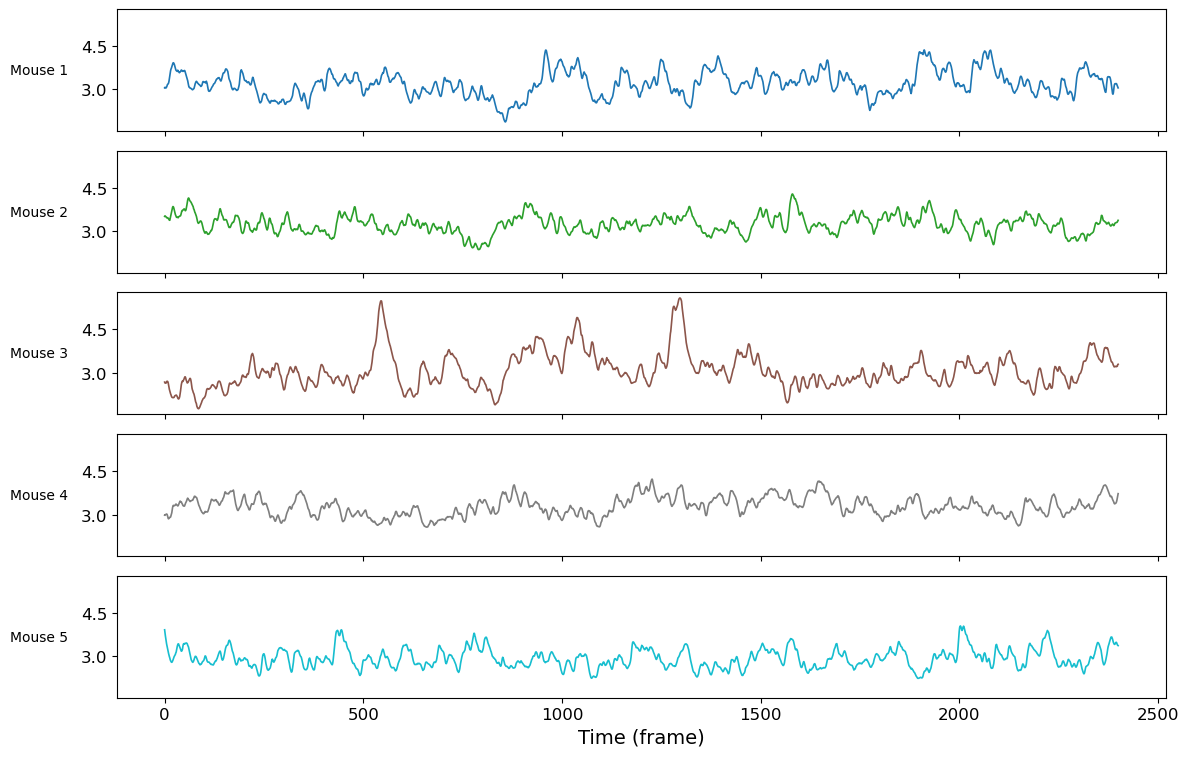

In [20]:
import matplotlib.pyplot as plt
import numpy as np
from matplotlib.ticker import MaxNLocator

num_mice = 5
stage0_frames = 2401
time_axis = np.arange(stage0_frames)
mouse_traces = []

for mouse_idx in range(num_mice):
    all_data = []
    for (file, time_index), data in all_trace.items():
        all_data.append(data)
    start = mouse_idx * 21
    end = start + 21
    mouse_traces_raw = all_data[start:end]
    concatenated = np.concatenate(mouse_traces_raw, axis=1)
    stage0_data = concatenated[:, :stage0_frames]
    mean_activity = stage0_data.mean(axis=0)
    mouse_traces.append(mean_activity)

fig, axes = plt.subplots(num_mice, 1, figsize=(12, 8), sharex=True)
colors = plt.cm.tab10(np.linspace(0, 1, num_mice))

global_min = min(trace.min() for trace in mouse_traces)
global_max = max(trace.max() for trace in mouse_traces)
margin = (global_max - global_min) * 0.05
global_min -= margin
global_max += margin

for i in range(num_mice):
    axes[i].plot(time_axis, mouse_traces[i], color=colors[i], linewidth=1.2)
    axes[i].set_ylabel(f'Mouse {i+1}', rotation=0, labelpad=30, va='center', fontsize=10)
    axes[i].grid(False)
    axes[i].set_ylim(global_min, global_max)
    axes[i].yaxis.set_major_locator(MaxNLocator(nbins=4, prune='both'))
    axes[i].ticklabel_format(axis='y', style='plain', useOffset=False)
    axes[i].tick_params(axis='y', labelsize=12)
    axes[i].tick_params(axis='x', labelsize=12)

axes[-1].set_xlabel('Time (frame)', fontsize=14)
plt.tight_layout(rect=[0, 0, 1, 0.96])
plt.savefig('stage0_mouse_traces.png', dpi=600, bbox_inches='tight')
plt.show()